In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors
import seaborn as sns

In [4]:
results_path = "/n/holylfs05/LABS/arguelles_delgado_lab/Everyone/jbook/double_cascade_identification/BinaryClassifier/save_best_incl_190300_batchsize_8/"
results_filename = results_path+"results.csv"
results = pd.read_csv(results_filename)

In [9]:
probable = results['event_weight']>=0.0
hnl = results['is_hnl']==1.0
hnl_mask = hnl & probable
background_mask = results['is_hnl']==0.0

tau_plus = results['pid']==16.0
tau_minus = results['pid']==-16.0
mu_plus = results['pid']==14.0
mu_minus = results['pid']==-14.0
e_plus = results['pid']==12.0
e_minus = results['pid']==-12.0

nutau_mask = (tau_plus | tau_minus) & probable
numu_mask = mu_plus | mu_minus
nue_mask = e_plus | e_minus

In [10]:
print(np.sum(results[background_mask]['event_weight']))
print(np.sum(results[hnl_mask]['event_weight']))

0.00013110678862995247
4.6239974396306596e-07


In [11]:
print(len(results[background_mask]))
print(len(results[hnl_mask]))

5942
13227


Text(0.5, 1.0, 'HNL classifier attempt')

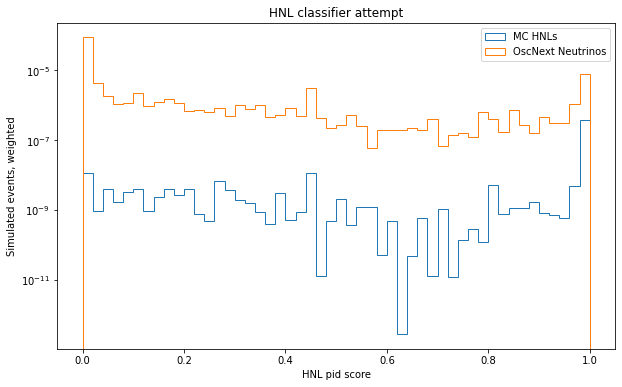

In [15]:
plt.figure(figsize=(10, 6))
# bins = np.logspace(-0.5, 4, 500)

plt.hist(results['hnl_likelihood'][hnl_mask], bins = 50, weights=results['event_weight'][hnl_mask], histtype="step", label="MC HNLs")
plt.hist(results['hnl_likelihood'][background_mask], bins = 50, histtype="step",weights=results[background_mask]['event_weight'], label="OscNext Neutrinos")


# plt.xscale('log')
plt.yscale('log')
plt.legend()
plt.xlabel('HNL pid score')
plt.ylabel('Simulated events, weighted')
plt.title("HNL classifier attempt")

Text(0.5, 1.0, 'Initial classifier attempt')

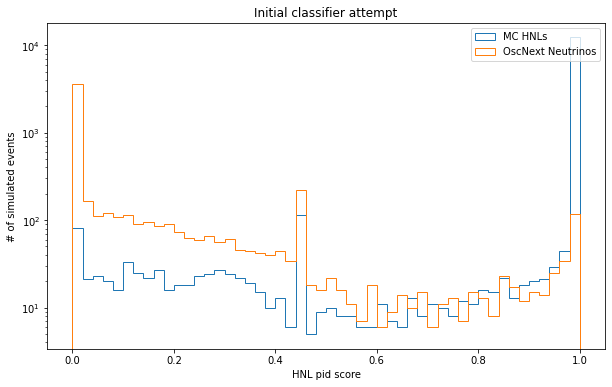

In [16]:
plt.figure(figsize=(10, 6))
# bins = np.logspace(-0.5, 4, 500)

plt.hist(results['hnl_likelihood'][hnl_mask], bins = 50, histtype="step", label="MC HNLs")
plt.hist(results['hnl_likelihood'][background_mask], bins = 50, histtype="step", label="OscNext Neutrinos")


# plt.xscale('log')
plt.yscale('log')
plt.legend()
plt.xlabel('HNL pid score')
plt.ylabel('# of simulated events')
plt.title("Initial classifier attempt")

Text(0, 0.5, 'Proportion of events')

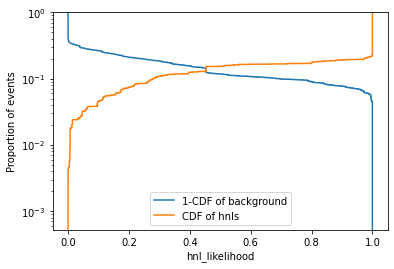

In [17]:
ax = sns.ecdfplot(
    data=results[background_mask], 
    x='hnl_likelihood', 
    stat='proportion', 
    complementary=True, 
    log_scale=[False, True],
    weights='event_weight',
    label="1-CDF of background")

ax1 = sns.ecdfplot(
    data=results[hnl_mask], 
    x='hnl_likelihood', 
    stat='proportion', 
    complementary=False, 
    log_scale=[False, True],
    weights='event_weight',
    label="CDF of hnls")

ax.legend()
ax.set_ylabel("Proportion of events")

In [18]:
def get_purity_and_efficiency(threshold = 0.38):
    background_pid_mask = results[background_mask]["hnl_likelihood"]>threshold
    hnl_pid_mask = results[hnl_mask]['hnl_likelihood']>threshold

    background_like_hnl = np.sum(results[background_mask][background_pid_mask]['event_weight'])
    hnl_like_hnl = np.sum(results[hnl_mask][hnl_pid_mask]['event_weight'])
    all_hnl = np.sum(results[hnl_mask]['event_weight'])
    
#     print("Threshold: " + str(threshold))
#     print("Purity: " + str(hnl_like_hnl/(hnl_like_hnl + background_like_hnl)))
#     print("Efficiency: " + str(hnl_like_hnl/all_hnl))
    
    purity = hnl_like_hnl/(hnl_like_hnl + background_like_hnl)
    efficiency = hnl_like_hnl/all_hnl
    
    return purity, efficiency

In [19]:
thresholds = np.linspace(0, 0.99, 100)
pur = np.zeros(len(thresholds))
eff = np.zeros(len(thresholds))
for i, t in enumerate(thresholds):
    pur[i], eff[i] = get_purity_and_efficiency(t)
    

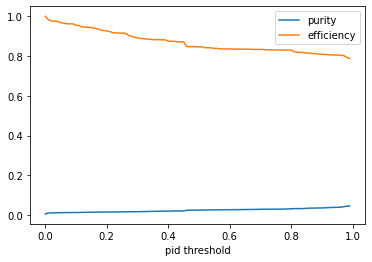

In [20]:
plt.plot(thresholds, pur, label="purity")
plt.plot(thresholds, eff, label = "efficiency")
plt.xlabel("pid threshold")
plt.legend()

In [21]:
print(get_purity_and_efficiency())

(0.01904129861283463, 0.881322005161198)


In [22]:
print(background_like_hnl)

NameError: name 'background_like_hnl' is not defined

Text(0, 0.5, 'Proportion of events above likelihood')

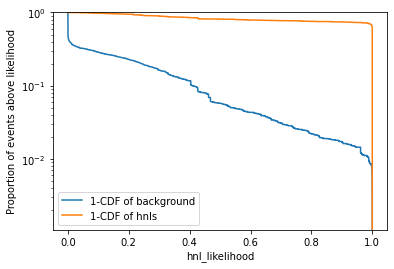

In [11]:
ax = sns.ecdfplot(
    data=results[background_mask], 
    x='hnl_likelihood', 
    stat='proportion', 
    complementary=True, 
    log_scale=[False, True],
    weights='event_weight', 
    label="1-CDF of background")
ax1 = sns.ecdfplot(
    data=results[hnl_mask], 
    x='hnl_likelihood', 
    stat='proportion', 
    complementary=True, 
    log_scale=[False, True],
    weights='event_weight',
    label="1-CDF of hnls")
ax.legend()
ax.set_ylabel("Proportion of events above likelihood")

Text(0.5, 1.0, 'Initial classifier attempt')

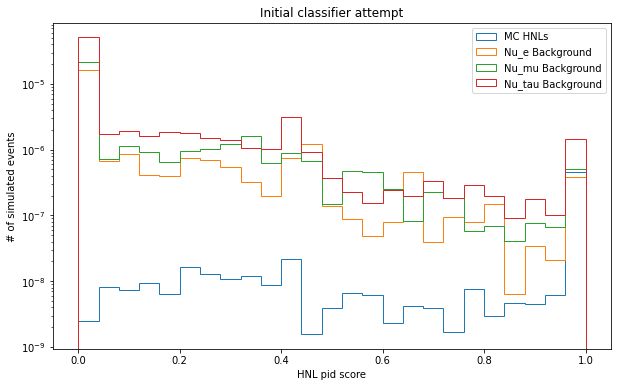

In [11]:
plt.figure(figsize=(10, 6))
# bins = np.logspace(-0.5, 4, 500)

plt.hist(results['hnl_likelihood'][hnl_mask], bins = 25, histtype="step", weights=results['event_weight'][hnl_mask], label="MC HNLs")
plt.hist(results['hnl_likelihood'][nue_mask], bins = 25, histtype="step", weights=results['event_weight'][nue_mask],label="Nu_e Background")
plt.hist(results['hnl_likelihood'][numu_mask], bins = 25, histtype="step", weights=results['event_weight'][numu_mask],label="Nu_mu Background")
plt.hist(results['hnl_likelihood'][nutau_mask], bins = 25, histtype="step", weights=results['event_weight'][nutau_mask],label="Nu_tau Background")

# plt.xscale('log')
plt.yscale('log')
plt.legend()
plt.xlabel('HNL pid score')
plt.ylabel('# of simulated events')
plt.title("Initial classifier attempt")

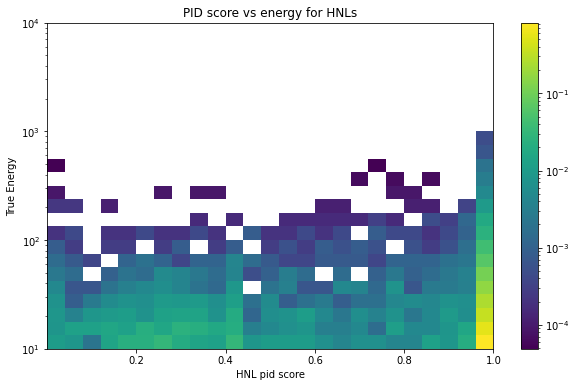

In [28]:
plt.figure(figsize=(10, 6))
xbins = 25
ybins = np.logspace(1, 4, xbins)
plt.hist2d(results['hnl_likelihood'][hnl_mask], results['energy'][hnl_mask], bins=[xbins, ybins], norm=colors.LogNorm(), density=True)

# plt.xscale('log')
plt.yscale('log')
# plt.legend()
plt.xlabel('HNL pid score')
plt.ylabel('True Energy')
plt.title("PID score vs energy for HNLs")
plt.colorbar()

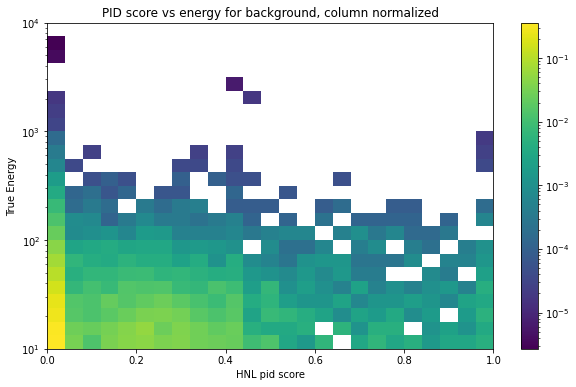

In [9]:
plt.figure(figsize=(10, 6))
xbins = 25
ybins = np.logspace(1, 4, xbins)
plt.hist2d(results['hnl_likelihood'][background_mask], results['energy'][background_mask], bins=[xbins, ybins], norm=colors.LogNorm(), density=True)

# plt.xscale('log')
plt.yscale('log')
# plt.legend()
plt.xlabel('HNL pid score')
plt.ylabel('True Energy')
plt.title("PID score vs energy for background, column normalized")
plt.colorbar()

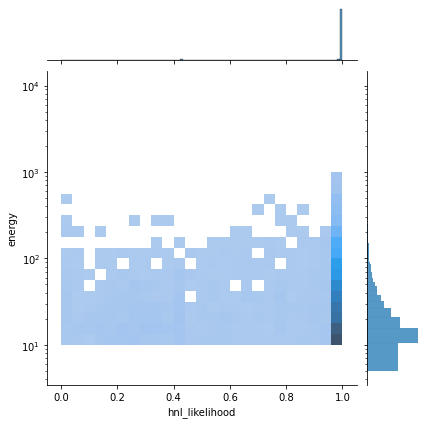

In [10]:
#maybe also use kind=kde?


g = sns.jointplot(data=results[hnl_mask], x="hnl_likelihood", y="energy", kind="hist", bins = [xbins, ybins])

# Set the axes to log scale
# g.ax_joint.set_xscale('log')
g.ax_joint.set_yscale('log')

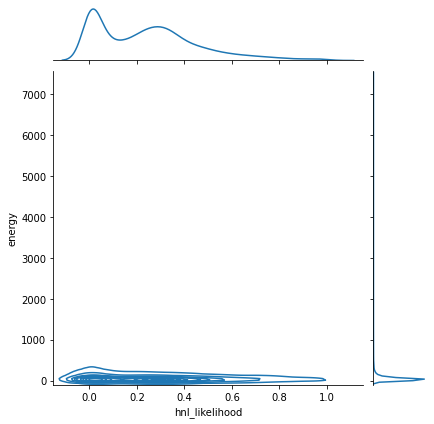

In [40]:
#maybe also use kind=kde?


g = sns.jointplot(data=results[background_mask], x="hnl_likelihood", y="energy", kind="kde")

# Set the axes to log scale
# g.ax_joint.set_xscale('log')
# g.ax_joint.set_yscale('log')